In [16]:
conexao.close()
print("Conexão encerrada.")

Conexão encerrada.


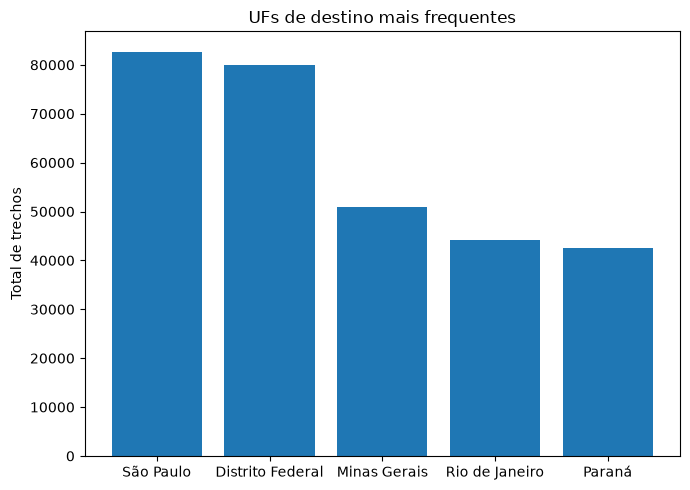

In [15]:
plt.figure(figsize=(7, 5))
plt.bar(df_uf_destino['destino_uf'], df_uf_destino['total_trechos'])
plt.ylabel('Total de trechos')
plt.title('UFs de destino mais frequentes')
plt.tight_layout()
plt.show()

In [14]:
df_uf_destino = pd.read_sql("""
    SELECT destino_uf, COUNT(*) AS total_trechos
    FROM silver_trecho
    WHERE destino_uf IS NOT NULL
    GROUP BY destino_uf
    ORDER BY total_trechos DESC
    LIMIT 5
""", conexao)

df_uf_destino

C:\Users\laris\AppData\Local\Temp\ipykernel_20756\2494843011.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_uf_destino = pd.read_sql("""


,destino_uf,total_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603


## Pergunta 6 — UF de destino que aparece em mais trechos

Consulta direta na camada Silver (`silver_trecho`), sem necessidade de JOIN.

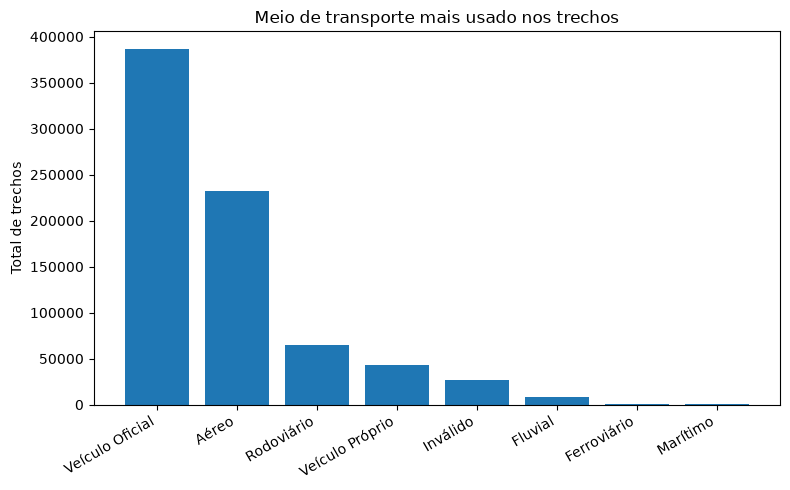

In [13]:
plt.figure(figsize=(8, 5))
plt.bar(df_transporte['meio_transporte'], df_transporte['total_trechos'])
plt.ylabel('Total de trechos')
plt.title('Meio de transporte mais usado nos trechos')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [12]:
df_transporte = pd.read_sql("""
    SELECT meio_transporte, COUNT(*) AS total_trechos
    FROM silver_trecho
    WHERE meio_transporte IS NOT NULL
    GROUP BY meio_transporte
    ORDER BY total_trechos DESC
""", conexao)

df_transporte

C:\Users\laris\AppData\Local\Temp\ipykernel_20756\4059048468.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_transporte = pd.read_sql("""


,meio_transporte,total_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


markdown
## Pergunta 5 — Meio de transporte mais usado nos trechos

Consulta direta na camada Silver (`silver_trecho`), sem necessidade de JOIN.

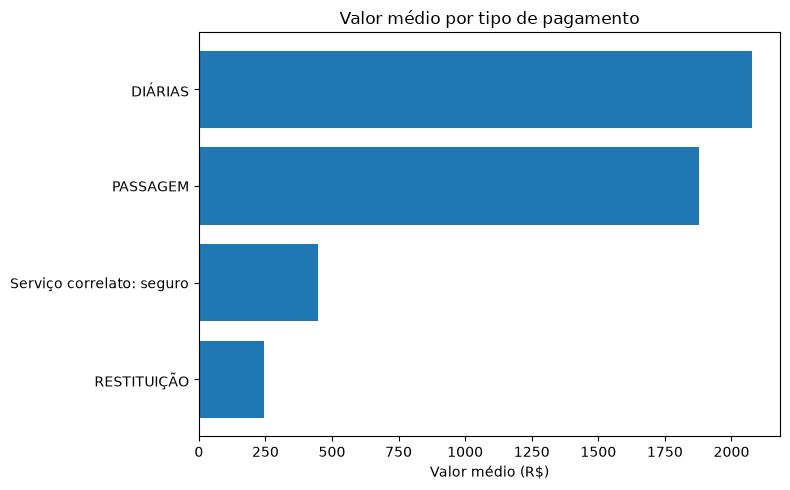

In [11]:
plt.figure(figsize=(8, 5))
plt.barh(df_pagamento['tipo_pagamento'], df_pagamento['valor_medio'])
plt.xlabel('Valor médio (R$)')
plt.title('Valor médio por tipo de pagamento')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [10]:
df_pagamento = pd.read_sql("""
    SELECT tipo_pagamento, COUNT(*) AS total_pagamentos, AVG(valor) AS valor_medio
    FROM silver_pagamento
    WHERE tipo_pagamento IS NOT NULL
    GROUP BY tipo_pagamento
    ORDER BY valor_medio DESC
""", conexao)

df_pagamento

C:\Users\laris\AppData\Local\Temp\ipykernel_20756\3821398053.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pagamento = pd.read_sql("""


,tipo_pagamento,total_pagamentos,valor_medio
0,DIÁRIAS,401463,2078.280299
1,PASSAGEM,188985,1878.344393
2,Serviço correlato: seguro,4894,447.514653
3,RESTITUIÇÃO,11574,245.702610


## Pergunta 4 — Tipo de pagamento com maior valor médio

Consulta direta na camada Silver (`silver_pagamento`), sem necessidade de JOIN.

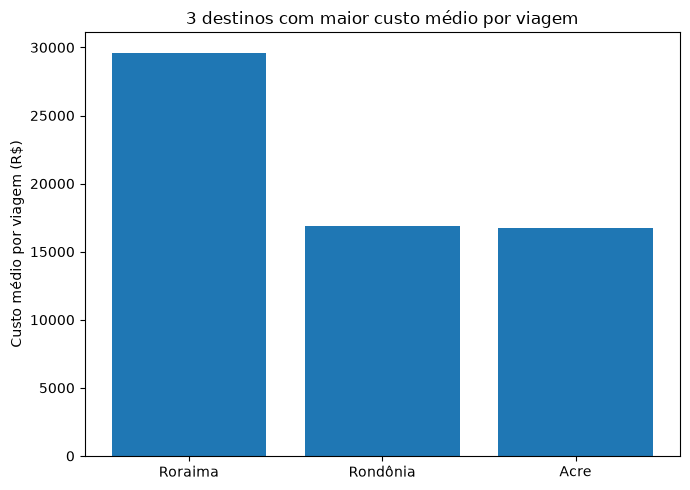

In [9]:
plt.figure(figsize=(7, 5))
plt.bar(df_destinos['uf_destino'], df_destinos['custo_medio_por_viagem'])
plt.ylabel('Custo médio por viagem (R$)')
plt.title('3 destinos com maior custo médio por viagem')
plt.tight_layout()
plt.show()

In [8]:
df_destinos = pd.read_sql("""
    SELECT uf_destino, total_viagens, custo_medio_por_viagem
    FROM gold_custo_medio_por_destino
    LIMIT 3
""", conexao)

df_destinos

C:\Users\laris\AppData\Local\Temp\ipykernel_20756\572604246.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_destinos = pd.read_sql("""


,uf_destino,total_viagens,custo_medio_por_viagem
0,Roraima,8850,29627.504205
1,Rondônia,7838,16903.419404
2,Acre,5399,16729.421839


## Pergunta 3 — Os 3 destinos (UF) com maior custo médio por viagem

Utiliza a camada Gold (`gold_custo_medio_por_destino`), construída com JOIN
entre `silver_trecho` e `silver_viagem`.

In [7]:
orgao_top = df_orgaos.iloc[0]
print(f"Órgão que mais pagou: {orgao_top['orgao']}")
print(f"Custo total: R$ {orgao_top['custo_total']:,.2f}")

Órgão que mais pagou: Fundo Nacional de Segurança Pública
Custo total: R$ 278,481,047.89


## Pergunta 2 — Qual órgão pagou mais no total

Resposta direta: a primeira linha da tabela Gold acima,
já ordenada do maior para o menor custo.

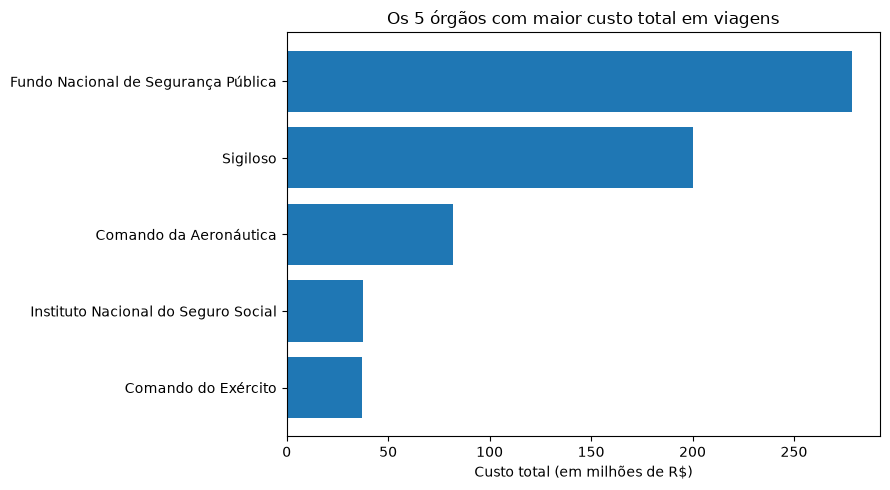

In [6]:
plt.figure(figsize=(9, 5))
plt.barh(df_orgaos['orgao'], df_orgaos['custo_total'] / 1_000_000)
plt.xlabel('Custo total (em milhões de R$)')
plt.title('Os 5 órgãos com maior custo total em viagens')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
df_orgaos = pd.read_sql("""
    SELECT orgao, total_viagens, custo_total
    FROM gold_custo_por_orgao
    LIMIT 5
""", conexao)

df_orgaos

C:\Users\laris\AppData\Local\Temp\ipykernel_20756\3510077771.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_orgaos = pd.read_sql("""


,orgao,total_viagens,custo_total
0,Fundo Nacional de Segurança Pública,24116,2.784810e+08
1,Sigiloso,51550,2.004848e+08
2,Comando da Aeronáutica,32336,8.176914e+07
3,Instituto Nacional do Seguro Social,7264,3.742760e+07
4,Comando do Exército,13285,3.687264e+07


## Pergunta 1 — Os 5 órgãos com maior custo total

Utiliza a camada Gold (`gold_custo_por_orgao`), construída com JOIN entre
`silver_pagamento` e `silver_viagem`, agrupando por órgão pagador.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import conectar

conexao = conectar()
print("Conectado ao banco com sucesso.")

Conectado ao banco com sucesso.


In [4]:
# Análise de Dados — Viagens a Serviço do Governo Federal

#Camada Gold: perguntas de negócio respondidas com SQL, tabelas e gráficos,
#a partir dos dados tratados na camada Silver.